# E-commerce Delivery Reliability Analytics

Locally executed companion evidence notebook. It reads measured outputs; it does not rerun training or claim execution on Kaggle.

Olist official Kaggle v2; CC BY-NC-SA 4.0; noncommercial only. AI-assisted portfolio study; no independently verified personal-skill claim.

Operations analyst prioritises delivery segments for investigation after outcomes mature. No purchase-time prediction or causal sanction.

In [1]:
from pathlib import Path
import json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/common.py').exists())
CASE = ROOT / 'projects/PRJ3_olist'
metrics = json.loads((CASE / 'results/metrics.json').read_text(encoding='utf-8'))
print(json.dumps(metrics, indent=2))

{
  "grain_rows": 99441,
  "grain_unique": true,
  "extract_proxy": "2018-10-17 17:30:18",
  "maturity_cutoff_60d": "2018-08-18 17:30:18",
  "eligible_all_dates": 96470,
  "late_all_dates": 6534,
  "late_rate_delivered_only": 0.06773090079817559,
  "mature_eligible": 95019,
  "mature_late": 6507,
  "mature_rate": 0.06848104063397847,
  "maturity_sensitivity": [
    {
      "maturity_days_assumption": 30,
      "all_orders": 99433,
      "eligible_delivered": 96470,
      "late": 6534,
      "late_rate_delivered_only": 0.06773090079817559,
      "without_eligible_delivery": 2963
    },
    {
      "maturity_days_assumption": 60,
      "all_orders": 97938,
      "eligible_delivered": 95019,
      "late": 6507,
      "late_rate_delivered_only": 0.06848104063397847,
      "without_eligible_delivery": 2919
    },
    {
      "maturity_days_assumption": 90,
      "all_orders": 89912,
      "eligible_delivered": 87186,
      "late": 6034,
      "late_rate_delivered_only": 0.06920835914022894,

In [2]:
for name in ['relational_review.json']:
    print(name)
    print(json.dumps(json.loads((CASE / 'results' / name).read_text(encoding='utf-8')), indent=2))

relational_review.json
{
  "rows_by_table": {
    "orders": 99441,
    "customers": 99441,
    "order_items": 112650,
    "order_payments": 103886,
    "order_reviews": 99224,
    "products": 32951,
    "sellers": 3095,
    "geolocation": 1000163,
    "translation": 71
  },
  "duplicate_primary_keys": {
    "orders": 0,
    "customers": 0,
    "products": 0,
    "sellers": 0,
    "translation": 0
  },
  "foreign_key_orphans": {
    "order_customer": 0,
    "item_order": 0,
    "item_product": 0,
    "item_seller": 0,
    "payment_order": 0,
    "review_order": 0
  },
  "review_id_repeats": 814,
  "review_order_composite_repeats": 0,
  "products_without_category": 610,
  "products_with_untranslated_nonnull_category": 13,
  "geolocation_zip_is_unique": false,
  "zip_prefix_types_preserved": {
    "customers": "string",
    "sellers": "string",
    "geolocation": "string"
  },
  "interpretation": "Do not assume review_id or ZIP is a unique join key. Translation is optional and unmatched c

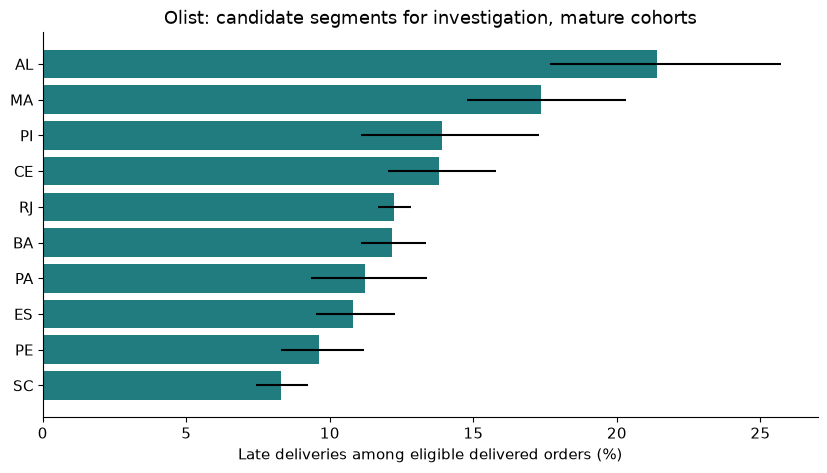

In [3]:
from IPython.display import Image, display
display(Image(filename=str(CASE / 'figures/investigation.png')))

## Interpretation and full recomputation

SQL retained 99,441 unique orders. All-period late rate is 6,534/96,470 = 6.77%, conditional on eligible delivered orders. Mature 60-day cohort rate: 6.85%.

Noncommercial Olist restriction. Undelivered orders are outside the late-rate denominator and explicitly counted. Export date is not known; latest purchase is a proxy, with 30/60/90-day maturity sensitivities. Wilson intervals assume independent Bernoulli outcomes; repeat-customer/route dependence and confounding remain.

From the portfolio root, use the environment and authorised inputs in `docs/REPRODUCIBILITY.md`, then execute `python src/olist_production.py`. Do not rerun the data audits merely to read these results. A standalone Kaggle environment requires adapting input mounting and installing the documented dependencies; no hosted execution is claimed.